# TripleNeurons Final Project, Notebook 1: Document Processing and Chunking Experiments

**ITC 508 Final Project: RAG Chatbot Development and Evaluation** | **Group:** TripleNeurons (Jude Vincent Gariando, Chris Jayson Kit Batac, Kc A. Sarmiento)
**Deliverables:** 2 (Chunking Experiments) and stages 1 to 4 of Deliverable 4

This notebook prepares the knowledge base of our waste-segregation assistant and runs the chunking experiment that decides the chunk size and overlap of the final chatbot. The knowledge base follows Table I of our WW-M2 proposal, which lists five authoritative sources: RA 9003, RA 6969, DENR DAO 2013-22, the NSWMC guidebook *Solid Waste Management Made Easy*, and the DENR/NSWMC RA 9003 information material. Two of these files are scanned images (DAO 2013-22 from page 3, and the one-page information material), so the notebook reads every page as text first and uses OCR only when a page has almost no text. For example, without OCR the 71-page DAO 2013-22 gives only two pages of text, so a question about busted lamps (waste number M507) could never be answered. In short, this notebook turns the five PDFs into clean, page-numbered text, tests five chunking configurations on the frozen test set, and selects one configuration using a rule that is written before the results are seen.

**How to run:** *Runtime → Change runtime type → T4 GPU*, then *Run all*. In Section 3, upload the five PDFs and the frozen test set file. OCR of the scanned pages takes about 10 to 15 minutes. At the end, the notebook downloads `TripleNeurons_NB1_Outputs.zip`, which is uploaded in Notebook 2.

*AI assistance:* the code in this notebook was drafted with a generative AI assistant (Claude) and was run and checked by the group. This is disclosed in Deliverable 7.

## 1. Install dependencies

This cell installs the same packages as the instructor's RAG template, plus Tesseract OCR and Poppler. Tesseract reads text from page images and Poppler converts PDF pages to images, and both are needed because two of our five sources are scanned. If Colab asks for a restart after the update, restart the runtime and run all cells again.

In [ ]:
!apt-get update -qq && apt-get install -y -qq tesseract-ocr poppler-utils
%pip -q install -U transformers accelerate sentence-transformers langchain-community langchain-text-splitters langchain-huggingface langchain-chroma chromadb pypdf openpyxl pytesseract pdf2image
import shutil as _sh
for _tool in ('tesseract', 'pdfinfo', 'pdftoppm'):
    print(f'{_tool:<10}', _sh.which(_tool) or 'NOT FOUND: re-run this cell')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libpoppler-private-dev_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking libpoppler-private-dev:amd64 (24.02.0-1ubuntu9.11) over (24.02.0-1ubuntu9.10) ...
Preparing to unpack .../libpoppler-dev_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking libpoppler-dev:amd64 (24.02.0-1ubuntu9.11) over (24.02.0-1ubuntu9.10) ...
Preparing to unpack .../libpoppler134_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking libpoppler134:amd64 (24.02.0-1ubuntu9.11) over (24.02.0-1ubuntu9.10) ...
Selecting previously unselected package poppler-utils.
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.11) ...
Setting up libpoppler134:amd64 (24.02.0-1ubuntu9.11) ...
Setting up poppler-

## 2. Configuration and the decision rule

This cell fixes every setting of the experiment and writes the decision rule before any result exists. A fair experiment changes only one thing at a time (Lecture 5), so the documents, the embedding model, Top-K and the test set stay the same, and only the chunk size and the overlap change across the five runs. Writing the rule first prevents us from choosing the configuration that "looks best" after seeing the numbers. For example, if C1 and C2 have almost the same Recall@3, the rule already says that MRR decides, so the choice cannot be argued afterwards. The chunk sizes are in characters, because the template's `RecursiveCharacterTextSplitter` counts characters, not tokens.

In [ ]:
import datetime, json, os, re, shutil, time, zipfile
from pathlib import Path
from zoneinfo import ZoneInfo

LOGS = {}


def now_ph():
    """Timestamp in Philippine time (Colab clocks run in UTC)."""
    return datetime.datetime.now(ZoneInfo("Asia/Manila")).isoformat(timespec="seconds")


def log(sheet, **row):
    """Add one timestamped row to a log sheet of Deliverable 4."""
    LOGS.setdefault(sheet, []).append(
        {"timestamp": now_ph(), "member": MEMBER, "notebook": NOTEBOOK_ID, **row})


def log_issue(stage, message):
    """Record a problem honestly instead of hiding it."""
    log("Issues_Log", stage=stage, issue=str(message))
    print(f"[ISSUE logged] {stage}: {message}")


def save_logs(folder):
    """Write every log sheet as <notebook>_<sheet>.csv so the next notebook can merge them."""
    import pandas as pd
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    for sheet, rows in LOGS.items():
        pd.DataFrame(rows).to_csv(folder / f"{NOTEBOOK_ID}__{sheet}.csv", index=False)
    print("Saved log sheets:", sorted(LOGS))


def zip_folder(folder, zip_path):
    folder = Path(folder)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in sorted(folder.rglob("*")):
            if p.is_file():
                zf.write(p, p.relative_to(folder))
    return zip_path


def folder_size_mb(folder):
    return round(sum(p.stat().st_size for p in Path(folder).rglob("*") if p.is_file()) / 1024**2, 2)


def norm(text):
    """Lower-case and collapse spaces, for phrase matching."""
    text = (text or "").replace("’", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", text).lower().strip()

import torch

MEMBER = "TripleNeurons"
NOTEBOOK_ID = "NB1"
GROUP_NAME = "TripleNeurons"

SOURCE_DIR = Path("/content/knowledge_base")
WORK_DIR = Path("/content/nb1_outputs")
for folder in (SOURCE_DIR, WORK_DIR):
    folder.mkdir(parents=True, exist_ok=True)

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
TOP_K = 3
OCR_MIN_CHARS = 50       # a page with fewer extracted characters is treated as scanned
OCR_DPI = 250

CONFIGS = [
    {"config": "C1", "chunk_size": 400,  "chunk_overlap": 50,  "tests": "Small chunks"},
    {"config": "C2", "chunk_size": 800,  "chunk_overlap": 100, "tests": "Medium chunks (lab baseline)"},
    {"config": "C3", "chunk_size": 1200, "chunk_overlap": 150, "tests": "Large chunks"},
    {"config": "C4", "chunk_size": 800,  "chunk_overlap": 0,   "tests": "Medium chunks, no overlap"},
    {"config": "C5", "chunk_size": 800,  "chunk_overlap": 160, "tests": "Medium chunks, 20% overlap"},
]

DECISION_RULE = [
    "1. Choose the configuration with the highest mean Recall@3 on the answerable questions.",
    "2. Every configuration within 0.05 of the best Recall@3 stays in the running; among them, choose the highest MRR.",
    "3. If MRR is also within 0.02, choose the configuration with the smaller average context (fewer retrieved characters), because a smaller prompt is faster for the LLM.",
]
DECISION_RULE_WRITTEN_AT = now_ph()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
print("Device:", DEVICE)
print("Configurations:", [c["config"] for c in CONFIGS])
print("Decision rule written at", DECISION_RULE_WRITTEN_AT)
for line in DECISION_RULE:
    print(" ", line)

Device: cuda
Configurations: ['C1', 'C2', 'C3', 'C4', 'C5']
Decision rule written at 2026-11-10T15:53:44+08:00
  1. Choose the configuration with the highest mean Recall@3 on the answerable questions.
  2. Every configuration within 0.05 of the best Recall@3 stays in the running; among them, choose the highest MRR.
  3. If MRR is also within 0.02, choose the configuration with the smaller average context (fewer retrieved characters), because a smaller prompt is faster for the LLM.


In [ ]:
import platform, sys
import torch


def environment_rows():
    import importlib.metadata as md
    rows = {"Python": sys.version.split()[0], "Platform": platform.platform(),
            "GPU": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
            "CUDA available": torch.cuda.is_available()}
    for pkg in ["torch", "transformers", "sentence-transformers", "langchain-core",
                "langchain-text-splitters", "langchain-chroma", "langchain-huggingface",
                "chromadb", "pypdf", "pytesseract", "pdf2image", "gradio"]:
        try:
            rows[pkg] = md.version(pkg)
        except Exception:
            rows[pkg] = "not installed"
    return rows


for key, value in environment_rows().items():
    log("Environment", item=key, value=str(value))
    print(f"{key:<26}: {value}")

Python                    : 3.13.16
Platform                  : Linux-6.6.159+-x86_64-with-glibc2.39
GPU                       : Tesla T4
CUDA available            : True
torch                     : 2.14.1+cu130
transformers              : 5.22.2
sentence-transformers     : 6.2.0
langchain-core            : 1.7.4
langchain-text-splitters  : 1.1.3
langchain-chroma          : 1.1.0
langchain-huggingface     : 1.2.3
chromadb                  : 1.5.9
pypdf                     : 7.0.0
pytesseract               : 0.3.13
pdf2image                 : 1.17.0
gradio                    : 6.31.0


## 3. Upload the five PDFs and the frozen test set

This cell uploads the knowledge-base PDFs and the frozen test set. The downloaded files have long names (for example `EMB-Republic-Act-9003-ENGLISH-REV2-12-1-2016.pdf`), so the cell renames each one to a short fixed name, such as `RA9003_Info_Material.pdf`, which is the same name used in the test set's gold pages. The cell stops with an error if any of the five sources is missing, because a missing source would silently lower every retrieval score.

In [ ]:
DOC_LABELS = {
    "RA_9003.pdf": "RA 9003",
    "RA_6969.pdf": "RA 6969",
    "DAO_2013-22.pdf": "DAO 2013-22",
    "NSWMC_Guidebook.pdf": "NSWMC Guidebook",
    "RA9003_Info_Material.pdf": "RA 9003 Information Material",
}


def canonical_name(filename):
    """Map the downloaded file name to the fixed name used in the test set."""
    n = filename.lower()
    if "6969" in n:
        return "RA_6969.pdf"
    if "dao" in n or "2013-22" in n:
        return "DAO_2013-22.pdf"
    if "guide" in n or "bluebook" in n:
        return "NSWMC_Guidebook.pdf"
    if "emb" in n or "english" in n or "info" in n:
        return "RA9003_Info_Material.pdf"
    if "9003" in n:
        return "RA_9003.pdf"
    return None

from google.colab import files

TEST_SET_PATH = None
uploaded = files.upload()
for filename in uploaded:
    name = Path(filename).name
    if name.lower().endswith((".xlsx", ".csv")) and "test" in name.lower():
        TEST_SET_PATH = WORK_DIR / ("test_set" + Path(name).suffix.lower())
        shutil.move(filename, TEST_SET_PATH)
        print("Test set saved:", TEST_SET_PATH)
        continue
    target = canonical_name(name)
    if target is None:
        print("Skipped (not a knowledge-base file):", name)
        continue
    shutil.move(filename, SOURCE_DIR / target)
    print(f"Saved: {name} -> {target}")

if TEST_SET_PATH is None:
    found = sorted(WORK_DIR.glob("test_set.*"))
    TEST_SET_PATH = found[0] if found else None

missing = sorted(set(DOC_LABELS) - {p.name for p in SOURCE_DIR.glob("*.pdf")})
if missing:
    raise ValueError(f"Missing knowledge-base files: {missing}")
if TEST_SET_PATH is None:
    raise ValueError("Upload the frozen test set (.xlsx or .csv with 'test' in its name).")
print("\nKnowledge base:", sorted(p.name for p in SOURCE_DIR.glob("*.pdf")))

Saving TripleNeurons_Final_Test_Set_DRAFT.xlsx to TripleNeurons_Final_Test_Set_DRAFT.xlsx
Test set saved: /content/nb1_outputs/test_set.xlsx

Knowledge base: ['DAO_2013-22.pdf', 'NSWMC_Guidebook.pdf', 'RA9003_Info_Material.pdf', 'RA_6969.pdf', 'RA_9003.pdf']


## 4. Document processing: text extraction, OCR and cleaning

This cell reads every page, uses OCR only for pages with fewer than 50 characters of text, and removes repeated header lines. Reading text first is faster and more accurate than OCR for the three text PDFs, while OCR is the only way to read the scanned pages. The cleaning step removes lines that appear on every page and carry no content: the Lawphil print header, date and URL in the two laws, and the "Revised Procedures and Standards..." header and "N | Page" footer in DAO 2013-22. For example, without cleaning, the DAO header would appear in 69 chunks and could be retrieved for any hazardous-waste question. Each page keeps its file name, document label, PDF page number and extraction method, and the result is saved as `processed_pages.jsonl`, which is the first checkpoint of Deliverable 4.

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from pypdf import PdfReader
from pdf2image import convert_from_path
import pytesseract

BOILERPLATE_PATTERNS = [
    r"^\d{1,2}/\d{1,2}/\d{2},\s*\d{1,2}:\d{2}\s*[AP]M\s+R\.A\.\s*\d+$",
    r"^https?://lawphil\.net/\S*\s+\d+/\d+$",
    r"^Today is \w+day, \w+ \d{1,2}, \d{4}$",
    r"^ConstitutionStatutesExecutive Issuances.*$",
    r"^The Lawphil Project - Arellano Law Foundation$",
    r"^Revised Procedures and Standards for the Management of Hazardous Wastes$",
    r"^\(Revising DAO 2004-36\)$",
    r"^\d+\s*\|\s*Pa\s*ge.*$",
]


def clean_page_text(text):
    # OCR splits the DAO running header over two lines, so remove it before the line filter.
    text = re.sub(r"Revised Procedures and Standards for the Management of\s+Hazardous\s+Wastes", "", text)
    text = re.sub(r"[({\[]Revising DAO 2004-36[)}\]]", "", text)
    # Table-of-contents dot leaders that OCR reads as "......ccsscss..."
    text = re.sub(r"\.{4,}[A-Za-z0-9.,:;\-]*", " ", text)
    lines = [ln for ln in text.split("\n")
             if not any(re.match(p, ln.strip()) for p in BOILERPLATE_PATTERNS)]
    text = "\n".join(lines)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def ocr_page(path, page_number):
    image = convert_from_path(str(path), dpi=OCR_DPI, first_page=page_number,
                              last_page=page_number)[0]
    return pytesseract.image_to_string(image)


def process_pdf(path):
    reader = PdfReader(str(path))
    pages = []
    for i, page in enumerate(reader.pages, start=1):
        pages.append({"source": path.name, "doc_label": DOC_LABELS[path.name], "page": i,
                      "raw_text": page.extract_text() or "", "method": "text"})
    need_ocr = [p for p in pages if len(p["raw_text"].strip()) < OCR_MIN_CHARS]
    if need_ocr:
        with ThreadPoolExecutor(max_workers=max(2, os.cpu_count() or 2)) as pool:
            texts = list(pool.map(lambda p: ocr_page(path, p["page"]), need_ocr))
        for p, text in zip(need_ocr, texts):
            p["raw_text"], p["method"] = text, "ocr"
    for p in pages:
        p["text"] = clean_page_text(p["raw_text"])
    return pages


PAGES = []
for path in sorted(SOURCE_DIR.glob("*.pdf")):
    start = time.perf_counter()
    try:
        pages = process_pdf(path)
    except Exception as exc:
        log_issue("1_Doc_Processing", f"{path.name}: {exc}")
        raise
    seconds = time.perf_counter() - start
    PAGES.extend(pages)
    n_ocr = sum(p["method"] == "ocr" for p in pages)
    empty = sum(len(p["text"]) < OCR_MIN_CHARS for p in pages)
    log("1_Doc_Processing", file=path.name, document=DOC_LABELS[path.name], pages=len(pages),
        text_pages=len(pages) - n_ocr, ocr_pages=n_ocr, empty_pages_after_processing=empty,
        chars_before_cleaning=sum(len(p["raw_text"]) for p in pages),
        chars_after_cleaning=sum(len(p["text"]) for p in pages), seconds=round(seconds, 2))
    print(f"{path.name:<28} pages={len(pages):>3}  ocr={n_ocr:>3}  empty={empty}  "
          f"chars={sum(len(p['text']) for p in pages):>7}  time={seconds:.1f}s")
    if empty:
        log_issue("1_Doc_Processing", f"{path.name}: {empty} page(s) have little or no text "
                  "after processing (check if they are blank, cover or image-only pages)")

with open(WORK_DIR / "processed_pages.jsonl", "w", encoding="utf-8") as f:
    for p in PAGES:
        f.write(json.dumps({k: p[k] for k in ("source", "doc_label", "page", "method", "text")},
                           ensure_ascii=False) + "\n")
print("\nTotal pages:", len(PAGES), "| saved processed_pages.jsonl")
sample = next(p for p in PAGES if p["source"] == "DAO_2013-22.pdf" and p["page"] == 18)
print("\nOCR sample, DAO 2013-22 page 18:\n", sample["text"][:800])

DAO_2013-22.pdf              pages= 71  ocr= 69  empty=0  chars= 105391  time=348.7s
NSWMC_Guidebook.pdf          pages= 56  ocr=  3  empty=1  chars=  87299  time=4.5s
[ISSUE logged] 1_Doc_Processing: NSWMC_Guidebook.pdf: 1 page(s) have little or no text after processing (check if they are blank, cover or image-only pages)
RA9003_Info_Material.pdf     pages=  1  ocr=  1  empty=0  chars=   3814  time=10.6s
RA_6969.pdf                  pages=  6  ocr=  0  empty=1  chars=  19966  time=0.2s
[ISSUE logged] 1_Doc_Processing: RA_6969.pdf: 1 page(s) have little or no text after processing (check if they are blank, cover or image-only pages)
RA_9003.pdf                  pages= 27  ocr=  0  empty=0  chars= 105531  time=1.1s

Total pages: 161 | saved processed_pages.jsonl

OCR sample, DAO 2013-22 page 18:
 Class

Description

Waste
Number

Pharmaceuticals and
drugs

Expired pharmaceuticals and drugs
stocked at producers and retailers’
facilities which contain hazardous
constituents harmful to the

## 5. Check that the test-set evidence exists in the processed text

This cell checks every anchor phrase of the frozen test set against the processed pages. The retrieval scores depend on the gold pages, so we must first prove that each gold page really contains the evidence after extraction and OCR. A phrase that is not found means one of three things: OCR misread a word, the page number in the test set is wrong, or the phrase was mistyped. For example, OCR can read the DAO waste number "I101" as "1101", so an anchor that uses such a code can fail even though the page is correct. Failed anchors are logged as issues and must be fixed in the test set before the experiment continues.

In [ ]:
import pandas as pd

TEST_COLUMNS = ["Q_ID", "Type", "Difficulty", "Category", "Question", "Reference_Answer",
                "Source_Document", "Source_Page", "Source_Section", "Gold_Pages", "Anchor_Phrases"]


def load_test_set(path):
    """Read the frozen test set (.xlsx sheet Test_Set, or .csv)."""
    path = Path(path)
    if path.suffix.lower() == ".xlsx":
        df = pd.read_excel(path, sheet_name="Test_Set", dtype=str)
    else:
        df = pd.read_csv(path, dtype=str)
    df = df.fillna("")
    missing = [c for c in TEST_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"Test set is missing columns: {missing}")
    df = df[TEST_COLUMNS]
    df = df[df["Q_ID"].str.strip() != ""].reset_index(drop=True)
    return df


def gold_set(row):
    """Gold pages as a set of (file name, page number)."""
    pairs = set()
    for item in str(row["Gold_Pages"]).split(";"):
        if ":" in item:
            doc, page = item.strip().rsplit(":", 1)
            if page.strip().isdigit():
                pairs.add((doc.strip(), int(page)))
    return pairs


def anchors(row):
    return [a.strip() for a in str(row["Anchor_Phrases"]).split("||") if a.strip()]

test_df = load_test_set(TEST_SET_PATH)
PAGE_TEXT = {(p["source"], p["page"]): norm(p["text"]) for p in PAGES}

anchor_rows = []
for _, row in test_df.iterrows():
    if row["Type"] != "Answerable":
        continue
    gold = gold_set(row)
    for phrase in anchors(row):
        in_gold = [f"{d}:{pg}" for (d, pg) in sorted(gold) if norm(phrase) in PAGE_TEXT.get((d, pg), "")]
        anywhere = [f"{d}:{pg}" for (d, pg), t in PAGE_TEXT.items() if norm(phrase) in t]
        anchor_rows.append({"Q_ID": row["Q_ID"], "anchor": phrase,
                            "found_in_gold_pages": "; ".join(in_gold) or "NOT FOUND",
                            "found_anywhere": "; ".join(anywhere[:6]) or "NOT FOUND"})
        if not in_gold:
            log_issue("Test set check", f"{row['Q_ID']}: anchor '{phrase}' not found on its gold pages")

anchor_df = pd.DataFrame(anchor_rows)
print(f"Questions: {len(test_df)} "
      f"({(test_df['Type'] == 'Answerable').sum()} answerable, "
      f"{(test_df['Type'] == 'Unanswerable').sum()} unanswerable)")
print("Anchors found on their gold pages:",
      (anchor_df["found_in_gold_pages"] != "NOT FOUND").sum(), "of", len(anchor_df))
anchor_df

Questions: 20 (15 answerable, 5 unanswerable)
Anchors found on their gold pages: 27 of 27


,Q_ID,anchor,found_in_gold_pages,found_anywhere
0,E1,properly marked or identified for on-site coll...,RA_9003.pdf:16,RA_9003.pdf:16
1,E2,The four types of waste,NSWMC_Guidebook.pdf:18,NSWMC_Guidebook.pdf:18
2,E2,can be sold to junk shops,NSWMC_Guidebook.pdf:18,NSWMC_Guidebook.pdf:18
3,E3,drain and place in a covered container,NSWMC_Guidebook.pdf:22,NSWMC_Guidebook.pdf:22
4,E3,Never place in a plastic bag,NSWMC_Guidebook.pdf:22,NSWMC_Guidebook.pdf:22
5,E4,Place residuals in old plastic bags,RA9003_Info_Material.pdf:1,RA9003_Info_Material.pdf:1
6,E4,hard cardboard,RA9003_Info_Material.pdf:1,RA9003_Info_Material.pdf:1
7,E5,short-term acute hazards,RA_6969.pdf:2,RA_6969.pdf:2
8,E5,long-term environmental hazards,RA_6969.pdf:2,RA_6969.pdf:2
9,A1,Special wastes shall refer to household hazard...,DAO_2013-22.pdf:11; RA_9003.pdf:4,DAO_2013-22.pdf:11; RA_9003.pdf:4


## 6. Embedding model and experiment functions

This cell loads all-MiniLM-L6-v2 and defines the functions that every configuration goes through: split, embed, store, retrieve and score. Using one set of functions for all five runs makes the comparison fair, because only the two chunking values change. The embeddings are normalized, so Chroma's distance ranks chunks the same way as cosine similarity. The cell also prints the model's maximum input length, because all-MiniLM-L6-v2 reads at most 256 word pieces and cuts the rest. For example, a 1200-character chunk is often longer than 256 word pieces, so its last part is not represented in the vector, which is one reason large chunks can retrieve worse even though they hold more text.

In [ ]:
def retrieval_metrics(docs, gold):
    """Precision@K, Recall@K, Hit@K and reciprocal rank against the gold pages."""
    keys = [(d.metadata.get("source"), d.metadata.get("page")) for d in docs]
    relevant = [k in gold for k in keys]
    k = max(len(keys), 1)
    first = next((i for i, r in enumerate(relevant, start=1) if r), None)
    return {
        "precision_at_k": sum(relevant) / k,
        "recall_at_k": len(set(keys) & gold) / len(gold) if gold else None,
        "hit_at_k": int(any(relevant)),
        "reciprocal_rank": (1 / first) if first else 0.0,
        "relevant_flags": "".join("1" if r else "0" for r in relevant),
    }

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


start = time.perf_counter()
embeddings = HuggingFaceEmbeddings(model_name=EMBEDDING_MODEL, model_kwargs={"device": DEVICE},
                                   encode_kwargs={"normalize_embeddings": True})
EMBED_LOAD_S = time.perf_counter() - start
ST_MODEL = embeddings._client
MAX_SEQ = ST_MODEL.max_seq_length
print(f"Embedding model loaded in {EMBED_LOAD_S:.1f}s on {ST_MODEL.device}; max input = {MAX_SEQ} word pieces")

PAGE_DOCS = [Document(page_content=p["text"],
                      metadata={"source": p["source"], "doc_label": p["doc_label"],
                                "page": p["page"], "method": p["method"]})
             for p in PAGES if p["text"].strip()]


def make_chunks(cfg):
    splitter = RecursiveCharacterTextSplitter(chunk_size=cfg["chunk_size"],
                                              chunk_overlap=cfg["chunk_overlap"],
                                              add_start_index=True)
    chunks = splitter.split_documents(PAGE_DOCS)
    for i, c in enumerate(chunks):
        c.metadata["chunk_id"] = f"{cfg['config']}-{i:05d}"
    return chunks


def build_store(chunks, name):
    texts = [c.page_content for c in chunks]
    sync(); t0 = time.perf_counter()
    vectors = embeddings.embed_documents(texts)
    sync(); embed_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    store = Chroma(collection_name=name, embedding_function=embeddings)
    for i in range(0, len(texts), 1000):
        part = chunks[i:i + 1000]
        store._collection.add(ids=[c.metadata["chunk_id"] for c in part],
                              embeddings=vectors[i:i + 1000], documents=texts[i:i + 1000],
                              metadatas=[c.metadata for c in part])
    store_s = time.perf_counter() - t0
    return store, embed_s, store_s


def retrieve(store, question, k=TOP_K):
    sync(); t0 = time.perf_counter()
    vector = embeddings.embed_query(question)
    sync(); t1 = time.perf_counter()
    pairs = store.similarity_search_by_vector_with_relevance_scores(vector, k=k)
    t2 = time.perf_counter()
    # Chroma returns squared L2 distance; for normalized vectors cosine = 1 - d / 2
    return [d for d, _ in pairs], [1 - float(s) / 2 for _, s in pairs], t1 - t0, t2 - t1


print("Pages with text:", len(PAGE_DOCS))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded in 24.7s on cuda:0; max input = 256 word pieces
Pages with text: 159


## 7. Run the five chunking configurations

This cell builds a separate index for each configuration and asks all 20 test questions against it. Each run logs its chunk statistics, embedding and storing times, and the Top-3 chunks of every question with their similarity scores, so the comparison in Section 8 is based on actual retrieval outputs and not on estimates. Retrieval quality is measured against the gold pages of the test set: a retrieved chunk is relevant when it comes from a page that holds the evidence. For example, for question A4 (busted lamps), a chunk from DAO 2013-22 page 18 is relevant, while a chunk from the DAO table of contents is not, even if it contains the word "lamps". The unanswerable questions are also retrieved, so we can see how similar the "best" chunks are when the answer does not exist.

In [ ]:
chunk_stats, per_question, chunk_files = [], [], {}

for cfg in CONFIGS:
    name = cfg["config"]
    t0 = time.perf_counter()
    chunks = make_chunks(cfg)
    split_s = time.perf_counter() - t0
    lengths = [len(c.page_content) for c in chunks]
    wordpieces = [len(ST_MODEL.tokenizer.tokenize(c.page_content)) for c in chunks]
    over = sum(w > MAX_SEQ for w in wordpieces)

    chunk_path = WORK_DIR / f"chunks_{name}_{cfg['chunk_size']}_{cfg['chunk_overlap']}.jsonl"
    with open(chunk_path, "w", encoding="utf-8") as f:
        for c in chunks:
            f.write(json.dumps({"chunk_id": c.metadata["chunk_id"], **{k: c.metadata[k] for k in
                                ("source", "doc_label", "page", "method", "start_index")},
                                "text": c.page_content}, ensure_ascii=False) + "\n")
    chunk_files[name] = chunk_path.name

    store, embed_s, store_s = build_store(chunks, f"exp_{name}")
    row = {**cfg, "n_chunks": len(chunks), "avg_chars": round(sum(lengths) / len(lengths), 1),
           "min_chars": min(lengths), "max_chars": max(lengths),
           "ocr_chunks": sum(c.metadata["method"] == "ocr" for c in chunks),
           "chunks_over_embedding_limit": over,
           "pct_over_embedding_limit": round(100 * over / len(chunks), 1),
           "split_s": round(split_s, 3), "embedding_s": round(embed_s, 2),
           "store_s": round(store_s, 2), "indexing_s": round(split_s + embed_s + store_s, 2)}
    chunk_stats.append(row)
    log("2_Chunking", config=name, chunk_size=cfg["chunk_size"], chunk_overlap=cfg["chunk_overlap"],
        n_chunks=row["n_chunks"], avg_chars=row["avg_chars"], min_chars=row["min_chars"],
        max_chars=row["max_chars"], split_s=row["split_s"], checkpoint=chunk_path.name)
    log("3_Embedding", config=name, model=EMBEDDING_MODEL, dimension=len(embeddings.embed_query("test")),
        vectors=len(chunks), device=str(ST_MODEL.device), embedding_s=row["embedding_s"],
        chunks_over_limit=over)
    log("4_Vector_DB", config=name, collection=f"exp_{name}", vector_count=store._collection.count(),
        persist_path="in-memory (experiment only)", store_s=row["store_s"])

    for _, q in test_df.iterrows():
        docs, scores, emb_s, search_s = retrieve(store, q["Question"])
        gold = gold_set(q)
        m = retrieval_metrics(docs, gold) if q["Type"] == "Answerable" else {}
        per_question.append({
            "config": name, "chunk_size": cfg["chunk_size"], "chunk_overlap": cfg["chunk_overlap"],
            "Q_ID": q["Q_ID"], "Type": q["Type"], "Difficulty": q["Difficulty"],
            "retrieved": "; ".join(f"{d.metadata['source']}:{d.metadata['page']}" for d in docs),
            "chunk_ids": "; ".join(d.metadata["chunk_id"] for d in docs),
            "scores": "; ".join(f"{s:.4f}" for s in scores), "top1_score": round(scores[0], 4),
            "context_chars": sum(len(d.page_content) for d in docs),
            "query_embedding_s": round(emb_s, 4), "vector_search_s": round(search_s, 4),
            **m, "top1_text": docs[0].page_content[:300] if docs else ""})
    log("5_Retrieval", config=name, questions=len(test_df), top_k=TOP_K,
        mean_retrieval_s=round(sum(r["query_embedding_s"] + r["vector_search_s"]
                                   for r in per_question if r["config"] == name) / len(test_df), 4))
    store.delete_collection()
    print(f"{name}: {row['n_chunks']} chunks, avg {row['avg_chars']} chars, "
          f"{row['pct_over_embedding_limit']}% over the embedding limit, indexing {row['indexing_s']}s")

stats_df = pd.DataFrame(chunk_stats)
pq_df = pd.DataFrame(per_question)
stats_df

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (311 > 256). Running this sequence through the model will result in indexing errors


C1: 1030 chunks, avg 318.2 chars, 0.0% over the embedding limit, indexing 3.08s
C2: 529 chunks, avg 635.9 chars, 0.2% over the embedding limit, indexing 1.69s
C3: 365 chunks, avg 935.3 chars, 8.8% over the embedding limit, indexing 1.23s
C4: 508 chunks, avg 632.9 chars, 0.2% over the embedding limit, indexing 1.38s
C5: 558 chunks, avg 650.2 chars, 0.2% over the embedding limit, indexing 1.58s


,config,chunk_size,chunk_overlap,tests,n_chunks,avg_chars,min_chars,max_chars,ocr_chunks,chunks_over_embedding_limit,pct_over_embedding_limit,split_s,embedding_s,store_s,indexing_s
0,C1,400,50,Small chunks,1030,318.2,1,400,378,0,0.0,0.020,1.94,1.12,3.08
1,C2,800,100,Medium chunks (lab baseline),529,635.9,1,800,189,1,0.2,0.026,1.15,0.51,1.69
2,C3,1200,150,Large chunks,365,935.3,1,1199,130,32,8.8,0.012,0.78,0.43,1.23
3,C4,800,0,"Medium chunks, no overlap",508,632.9,1,800,187,1,0.2,0.014,0.87,0.49,1.38
4,C5,800,160,"Medium chunks, 20% overlap",558,650.2,1,800,196,1,0.2,0.015,0.96,0.60,1.58


## 8. Compare the configurations and apply the decision rule

This cell averages the retrieval metrics over the 15 answerable questions and applies the rule from Section 2 step by step. Showing each step makes the choice auditable, because Sir can see which configurations stayed in the running and why one was removed. The table also shows the results by difficulty, since multi-source "Difficult" questions usually lose recall first when chunks are small. For example, if C1 has the best Recall@3 for Easy questions but the lowest for Difficult ones, the overall mean hides that trade-off, so it is reported in a separate table and discussed in the paper.

In [ ]:
ans = pq_df[pq_df["Type"] == "Answerable"]
summary = (ans.groupby("config")
           .agg(precision_at_3=("precision_at_k", "mean"), recall_at_3=("recall_at_k", "mean"),
                hit_at_3=("hit_at_k", "mean"), mrr=("reciprocal_rank", "mean"),
                avg_context_chars=("context_chars", "mean"))
           .round(4).reset_index())
unans = pq_df[pq_df["Type"] == "Unanswerable"].groupby("config")["top1_score"].mean().round(4)
summary["unanswerable_mean_top1_score"] = summary["config"].map(unans)
summary = stats_df[["config", "chunk_size", "chunk_overlap", "n_chunks", "avg_chars",
                    "pct_over_embedding_limit", "indexing_s"]].merge(summary, on="config")

by_difficulty = (ans.pivot_table(index="config", columns="Difficulty", values="recall_at_k",
                                 aggfunc="mean").round(4).add_prefix("recall_at_3_").reset_index())

steps = []
best_recall = summary["recall_at_3"].max()
step1 = summary[summary["recall_at_3"] >= best_recall - 0.05]
steps.append(f"Step 1: best Recall@3 = {best_recall:.4f}; within 0.05: {list(step1['config'])}")
best_mrr = step1["mrr"].max()
step2 = step1[step1["mrr"] >= best_mrr - 0.02]
steps.append(f"Step 2: best MRR among them = {best_mrr:.4f}; within 0.02: {list(step2['config'])}")
if len(step2) > 1:
    chosen = step2.sort_values("avg_context_chars").iloc[0]
    steps.append(f"Step 3: smallest average context among {list(step2['config'])} -> {chosen['config']}")
else:
    chosen = step2.iloc[0]
    steps.append(f"Step 3: not needed; {chosen['config']} is the only one left")

CHOSEN = next(c for c in CONFIGS if c["config"] == chosen["config"])
for s in steps:
    print(s)
print(f"\nSELECTED: {CHOSEN['config']} (chunk size {CHOSEN['chunk_size']}, "
      f"overlap {CHOSEN['chunk_overlap']}, Top-{TOP_K})")
decision = {"chosen": CHOSEN, "top_k": TOP_K, "embedding_model": EMBEDDING_MODEL,
            "rule": DECISION_RULE, "rule_written_at": DECISION_RULE_WRITTEN_AT,
            "steps": steps, "decided_at": now_ph(), "decided_by": MEMBER}
(WORK_DIR / "decision.json").write_text(json.dumps(decision, indent=2), encoding="utf-8")
display(summary)
display(by_difficulty)

Step 1: best Recall@3 = 0.5778; within 0.05: ['C3', 'C4']
Step 2: best MRR among them = 0.6444; within 0.02: ['C4']
Step 3: not needed; C4 is the only one left

SELECTED: C4 (chunk size 800, overlap 0, Top-3)


,config,chunk_size,chunk_overlap,n_chunks,avg_chars,pct_over_embedding_limit,indexing_s,precision_at_3,recall_at_3,hit_at_3,mrr,avg_context_chars,unanswerable_mean_top1_score
0,C1,400,50,1030,318.2,0.0,3.08,0.3333,0.4889,0.6667,0.6000,1048.0667,0.5492
1,C2,800,100,529,635.9,0.2,1.69,0.2889,0.4611,0.6667,0.5778,2048.4000,0.5485
2,C3,1200,150,365,935.3,8.8,1.23,0.2889,0.5389,0.6667,0.5222,3073.2000,0.5408
3,C4,800,0,508,632.9,0.2,1.38,0.2889,0.5778,0.8000,0.6444,2033.9333,0.5411
4,C5,800,160,558,650.2,0.2,1.58,0.2889,0.4556,0.6000,0.5556,2063.2000,0.5497


Difficulty,config,recall_at_3_Average,recall_at_3_Difficult,recall_at_3_Easy
0,C1,0.3000,0.3667,0.8
1,C2,0.3667,0.4167,0.6
2,C3,0.4667,0.3500,0.8
3,C4,0.3667,0.3667,1.0
4,C5,0.3000,0.4667,0.6


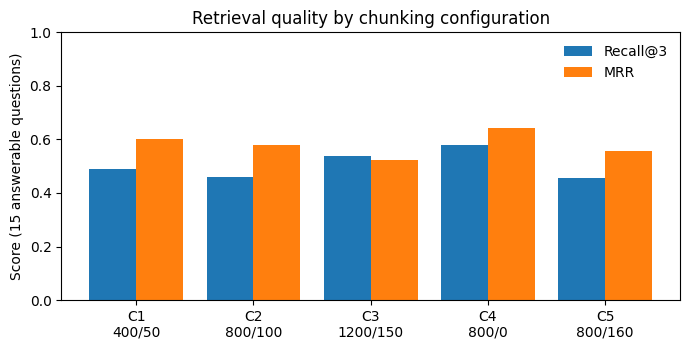

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.6))
x = range(len(summary))
ax.bar([i - 0.2 for i in x], summary["recall_at_3"], width=0.4, label="Recall@3")
ax.bar([i + 0.2 for i in x], summary["mrr"], width=0.4, label="MRR")
ax.set_xticks(list(x))
ax.set_xticklabels([f"{r.config}\n{r.chunk_size}/{r.chunk_overlap}" for r in summary.itertuples()])
ax.set_ylim(0, 1)
ax.set_ylabel("Score (15 answerable questions)")
ax.set_title("Retrieval quality by chunking configuration")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(WORK_DIR / "fig_chunking_retrieval.png", dpi=200)
plt.show()

## 9. Export Deliverable 2 and the hand-off package

This cell writes the chunking workbook, saves the logs of stages 1 to 5, and downloads the hand-off ZIP for Notebook 2. The workbook holds the configurations, the decision rule with its timestamp, the chunk statistics, every retrieved chunk per question, the summary, the step-by-step decision and the anchor check, so every number in the paper's chunking table can be traced to a sheet. The ZIP carries the processed pages, the chunk checkpoints, `decision.json`, the frozen test set and the logs, so Notebook 2 builds the final index from exactly the same text without running OCR again.

In [ ]:
XLSX = WORK_DIR / f"{GROUP_NAME}_Final_Chunking_Experiments.xlsx"
with pd.ExcelWriter(XLSX, engine="openpyxl") as xw:
    pd.DataFrame(CONFIGS).to_excel(xw, sheet_name="Configs", index=False)
    pd.DataFrame({"decision_rule": DECISION_RULE + [f"Written at {DECISION_RULE_WRITTEN_AT} by {MEMBER}"]}
                 ).to_excel(xw, sheet_name="Decision_Rule", index=False)
    stats_df.to_excel(xw, sheet_name="Chunk_Stats", index=False)
    pq_df.to_excel(xw, sheet_name="Retrieval_Per_Question", index=False)
    summary.to_excel(xw, sheet_name="Summary", index=False)
    by_difficulty.to_excel(xw, sheet_name="Recall_By_Difficulty", index=False)
    pd.DataFrame({"step": steps + [f"SELECTED: {CHOSEN['config']} ({CHOSEN['chunk_size']}/{CHOSEN['chunk_overlap']})"]}
                 ).to_excel(xw, sheet_name="Decision", index=False)
    anchor_df.to_excel(xw, sheet_name="Anchor_Check", index=False)
    pd.DataFrame(LOGS.get("1_Doc_Processing", [])).to_excel(xw, sheet_name="Doc_Processing", index=False)

save_logs(WORK_DIR / "logs")
zip_path = zip_folder(WORK_DIR, Path(f"/content/{GROUP_NAME}_NB1_Outputs.zip"))
print("Workbook:", XLSX.name)
print("Hand-off ZIP:", zip_path, f"({Path(zip_path).stat().st_size / 1024**2:.1f} MB)")

from google.colab import files
files.download(str(XLSX))
files.download(str(zip_path))

Saved log sheets: ['1_Doc_Processing', '2_Chunking', '3_Embedding', '4_Vector_DB', '5_Retrieval', 'Environment', 'Issues_Log']
Workbook: TripleNeurons_Final_Chunking_Experiments.xlsx
Hand-off ZIP: /content/TripleNeurons_NB1_Outputs.zip (0.7 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>